In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 1. Define the file paths
file1 = r"D:\Assessment\Flock Energy Assessment\raw_dataset\RAW_House1_Part1.csv"
file2 = r"D:\Assessment\Flock Energy Assessment\raw_dataset\RAW_House1_Part2.csv"

In [3]:
# 2. Load both CSV files
print("Loading Part 1...")
df1 = pd.read_csv(file1)

print("Loading Part 2...")
df2 = pd.read_csv(file2)

Loading Part 1...
Loading Part 2...


In [4]:
# 3. Combine them into a single DataFrame
print("Concatenating DataFrames...")
df = pd.concat([df1, df2], ignore_index=True)

Concatenating DataFrames...


In [5]:
df.head()

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2013-10-09 14:06:31,1381327591,526.0,75.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2013-10-09 14:06:46,1381327606,540.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0
3,2013-10-09 14:07:01,1381327621,532.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2013-10-09 14:07:15,1381327634,540.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0


In [6]:
# 4. Basic Data Analysis
print("Shape of DataFrame:", df.shape)
print("Columns of DataFrame:", df.columns)
print("Data Types of DataFrame:", df.dtypes)
print("First 5 rows of DataFrame:")
print(df.head())

Shape of DataFrame: (8518763, 12)
Columns of DataFrame: Index(['Time', 'Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3',
       'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8',
       'Appliance9'],
      dtype='str')
Data Types of DataFrame: Time              str
Unix            int64
Aggregate     float64
Appliance1    float64
Appliance2    float64
Appliance3    float64
Appliance4    float64
Appliance5    float64
Appliance6    float64
Appliance7    float64
Appliance8    float64
Appliance9    float64
dtype: object
First 5 rows of DataFrame:
                  Time        Unix  Aggregate  Appliance1  Appliance2  \
0  2013-10-09 14:06:17  1381327577      523.0        74.0         0.0   
1  2013-10-09 14:06:31  1381327591      526.0        75.0         0.0   
2  2013-10-09 14:06:46  1381327606      540.0        74.0         0.0   
3  2013-10-09 14:07:01  1381327621      532.0        74.0         0.0   
4  2013-10-09 14:07:15  1381327634      540.0        

In [7]:
# 5. Check for null values
print("Null values in DataFrame:")
print(df.isnull().sum())
print("Percentage of null values in DataFrame:")
print(df.isnull().mean() * 100)

Null values in DataFrame:
Time                0
Unix                0
Aggregate      188973
Appliance1     437890
Appliance2     459468
Appliance3     311961
Appliance4     510963
Appliance5     497223
Appliance6     342337
Appliance7     232752
Appliance8     390705
Appliance9    1911811
dtype: int64
Percentage of null values in DataFrame:
Time           0.000000
Unix           0.000000
Aggregate      2.218315
Appliance1     5.140300
Appliance2     5.393600
Appliance3     3.662046
Appliance4     5.998089
Appliance5     5.836798
Appliance6     4.018623
Appliance7     2.732228
Appliance8     4.586405
Appliance9    22.442355
dtype: float64


In [8]:
# 6. Check for duplicate rows
print("Duplicate rows in DataFrame:")
print(df.duplicated().sum())
print("Percentage of duplicate rows in DataFrame:")
print(df.duplicated().mean() * 100)

Duplicate rows in DataFrame:
595940
Percentage of duplicate rows in DataFrame:
6.995616617107436


In [9]:
# 7. Convert Time to datetime objects
df['Time'] = pd.to_datetime(df['Time'])

In [10]:
# 8. Sort by Time
df = df.sort_values(by='Time')

In [11]:
# 3. Remove duplicates using a stated rule
# Rule: If multiple readings happen at the exact same second, keep the first recorded reading.
df = df.drop_duplicates(subset=['Time'], keep='first')

In [12]:
# 4. Set Time as the index for resampling
df = df.set_index('Time')
# Drop the Unix column as it is redundant now that 'Time' is the datetime index
df = df.drop(columns=['Unix'])

In [22]:
def data_analysis(df: pd.DataFrame) -> None:
    print(df.dtypes)
    print(df.shape)
    print(df.head())
    # Check for null values
    print("Null values in DataFrame:")
    print(df.isnull().sum())
    print("Percentage of null values in DataFrame:")
    print(df.isnull().mean() * 100)
    # Check for duplicate rows
    print("Duplicate rows in DataFrame:")
    print(df.duplicated().sum())
    print("Percentage of duplicate rows in DataFrame:")
    print(df.duplicated().mean() * 100)
    print("Duplicate indices in DataFrame:",df.index.duplicated().sum())


In [23]:
data_analysis(df=df)

Aggregate     float64
Appliance1    float64
Appliance2    float64
Appliance3    float64
Appliance4    float64
Appliance5    float64
Appliance6    float64
Appliance7    float64
Appliance8    float64
Appliance9    float64
dtype: object
(7757212, 10)
                     Aggregate  Appliance1  Appliance2  Appliance3  \
Time                                                                 
2013-10-09 14:06:17      523.0        74.0         0.0        69.0   
2013-10-09 14:06:31      526.0        75.0         0.0        69.0   
2013-10-09 14:06:46      540.0        74.0         0.0        68.0   
2013-10-09 14:07:01      532.0        74.0         0.0        68.0   
2013-10-09 14:07:15      540.0        74.0         0.0        69.0   

                     Appliance4  Appliance5  Appliance6  Appliance7  \
Time                                                                  
2013-10-09 14:06:17         0.0         0.0         0.0         0.0   
2013-10-09 14:06:31         0.0         0.0     

In [19]:
# Count rows where ALL columns are null (e.g., the entire house meter went offline)
all_null_rows = df.isnull().all(axis=1).sum()

# Count rows where SOME columns are null, but not all (e.g., just Appliance 9 dropped out)
some_null_rows = (df.isnull().any(axis=1) & ~df.isnull().all(axis=1)).sum()

print(f"Rows with ALL columns missing (Complete Outage): {all_null_rows:,}")
print(f"Rows with SOME columns missing (Partial Dropout): {some_null_rows:,}")

Rows with ALL columns missing (Complete Outage): 0
Rows with SOME columns missing (Partial Dropout): 2,363,335


In [25]:
# 1. Resample to 1-minute intervals
df_resampled = df.resample('1min').mean()

# 2. Create a DataFrame to store the gap sizes for each column independently
gap_sizes = pd.DataFrame(index=df_resampled.index, columns=df_resampled.columns)

for col in df_resampled.columns:
    is_missing = df_resampled[col].isnull()
    gap_groups = (is_missing != is_missing.shift()).cumsum()
    gap_sizes[col] = is_missing.groupby(gap_groups).transform('sum')

# 3. Add the flag column: True if ANY column at this timestamp has a gap > 3
df_resampled['Long_Outage_Flag'] = (gap_sizes > 3).any(axis=1)

# 4. Fill short gaps column by column
df_cleaned = df_resampled.copy()

for col in df_cleaned.columns:
    if col == 'Long_Outage_Flag':
        continue
    
    # Identify rows where THIS specific column is missing but the gap is 3 mins or less
    mask_short_gaps = df_resampled[col].isnull() & (gap_sizes[col] <= 3)
    
    # Apply forward fill only to those short gaps
    df_cleaned.loc[mask_short_gaps, col] = df_resampled[col].ffill()

print(f"Total minutes flagged as having at least one long outage: {df_cleaned['Long_Outage_Flag'].sum():,}")

Total minutes flagged as having at least one long outage: 215,387


In [26]:
data_analysis(df=df_cleaned)

Aggregate           float64
Appliance1          float64
Appliance2          float64
Appliance3          float64
Appliance4          float64
Appliance5          float64
Appliance6          float64
Appliance7          float64
Appliance8          float64
Appliance9          float64
Long_Outage_Flag       bool
dtype: object
(920031, 11)
                      Aggregate  Appliance1  Appliance2  Appliance3  \
Time                                                                  
2013-10-09 14:06:00  529.666667   74.333333         0.0   68.666667   
2013-10-09 14:07:00  543.875000   73.875000         0.0   68.750000   
2013-10-09 14:08:00  578.000000   73.100000         0.0   41.900000   
2013-10-09 14:09:00  638.300000   72.800000         0.0    0.000000   
2013-10-09 14:10:00  800.200000   72.000000         0.0    0.000000   

                     Appliance4  Appliance5  Appliance6  Appliance7  \
Time                                                                  
2013-10-09 14:06:00      

In [27]:
# Check for impossible negative values
print("--- Negative Values ---")
print((df_cleaned.drop(columns=['Long_Outage_Flag']) < 0).sum())

# Check for extreme values
print("\n--- Extreme Values (> 20,000W) ---")
print((df_cleaned.drop(columns=['Long_Outage_Flag']) > 20000).sum())

# See the absolute maximums for each column
print("\n--- Max Values ---")
print(df_cleaned.drop(columns=['Long_Outage_Flag']).max())

--- Negative Values ---
Aggregate     0
Appliance1    0
Appliance2    0
Appliance3    0
Appliance4    0
Appliance5    0
Appliance6    0
Appliance7    0
Appliance8    0
Appliance9    0
dtype: int64

--- Extreme Values (> 20,000W) ---
Aggregate      9
Appliance1     5
Appliance2     1
Appliance3     0
Appliance4    16
Appliance5     1
Appliance6     0
Appliance7     3
Appliance8     4
Appliance9     0
dtype: int64

--- Max Values ---
Aggregate     23965.750000
Appliance1    65549.000000
Appliance2    28086.000000
Appliance3    13247.400000
Appliance4    98301.000000
Appliance5    22185.666667
Appliance6     5734.400000
Appliance7    73725.000000
Appliance8    43710.000000
Appliance9    16384.500000
dtype: float64


In [30]:
for col in df_cleaned.columns:
    if col == 'Long_Outage_Flag':
        continue
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1
    mask = (df_cleaned[col] < max(0,(Q1 - 1.5 * IQR))) | (df_cleaned[col] > (Q3 + 1.5 * IQR))
    print(f"Number of outliers in column {col}: {mask.sum():,}")
    print(f"Percentage of outliers in column {col}: {mask.sum() / len(df_cleaned[col]):.2%}")

Number of outliers in column Aggregate: 100,529
Percentage of outliers in column Aggregate: 10.93%
Number of outliers in column Appliance1: 199,943
Percentage of outliers in column Appliance1: 21.73%
Number of outliers in column Appliance2: 1,481
Percentage of outliers in column Appliance2: 0.16%
Number of outliers in column Appliance3: 2,989
Percentage of outliers in column Appliance3: 0.32%
Number of outliers in column Appliance4: 4,310
Percentage of outliers in column Appliance4: 0.47%
Number of outliers in column Appliance5: 19,392
Percentage of outliers in column Appliance5: 2.11%
Number of outliers in column Appliance6: 8,007
Percentage of outliers in column Appliance6: 0.87%
Number of outliers in column Appliance7: 93,065
Percentage of outliers in column Appliance7: 10.12%
Number of outliers in column Appliance8: 151,137
Percentage of outliers in column Appliance8: 16.43%
Number of outliers in column Appliance9: 58,345
Percentage of outliers in column Appliance9: 6.34%


In [31]:
for col in df_cleaned.columns:
    if col == 'Long_Outage_Flag':
        continue

    print(f"\n{col}")
    print(df_cleaned[col].describe())


Aggregate
count    805596.000000
mean        477.717608
std         761.564498
min         113.500000
25%         186.400000
50%         245.777778
75%         449.000000
max       23965.750000
Name: Aggregate, dtype: float64

Appliance1
count    804010.000000
mean         19.369171
std         183.722474
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max       65549.000000
Name: Appliance1, dtype: float64

Appliance2
count    803140.000000
mean         16.805858
std          50.146424
min           0.000000
25%           0.000000
50%           0.000000
75%          45.266667
max       28086.000000
Name: Appliance2, dtype: float64

Appliance3
count    804172.000000
mean         29.417888
std          51.186871
min           0.000000
25%           0.000000
50%           0.000000
75%          69.666667
max       13247.400000
Name: Appliance3, dtype: float64

Appliance4
count    804787.000000
mean          5.173603
std         363.089063
min  

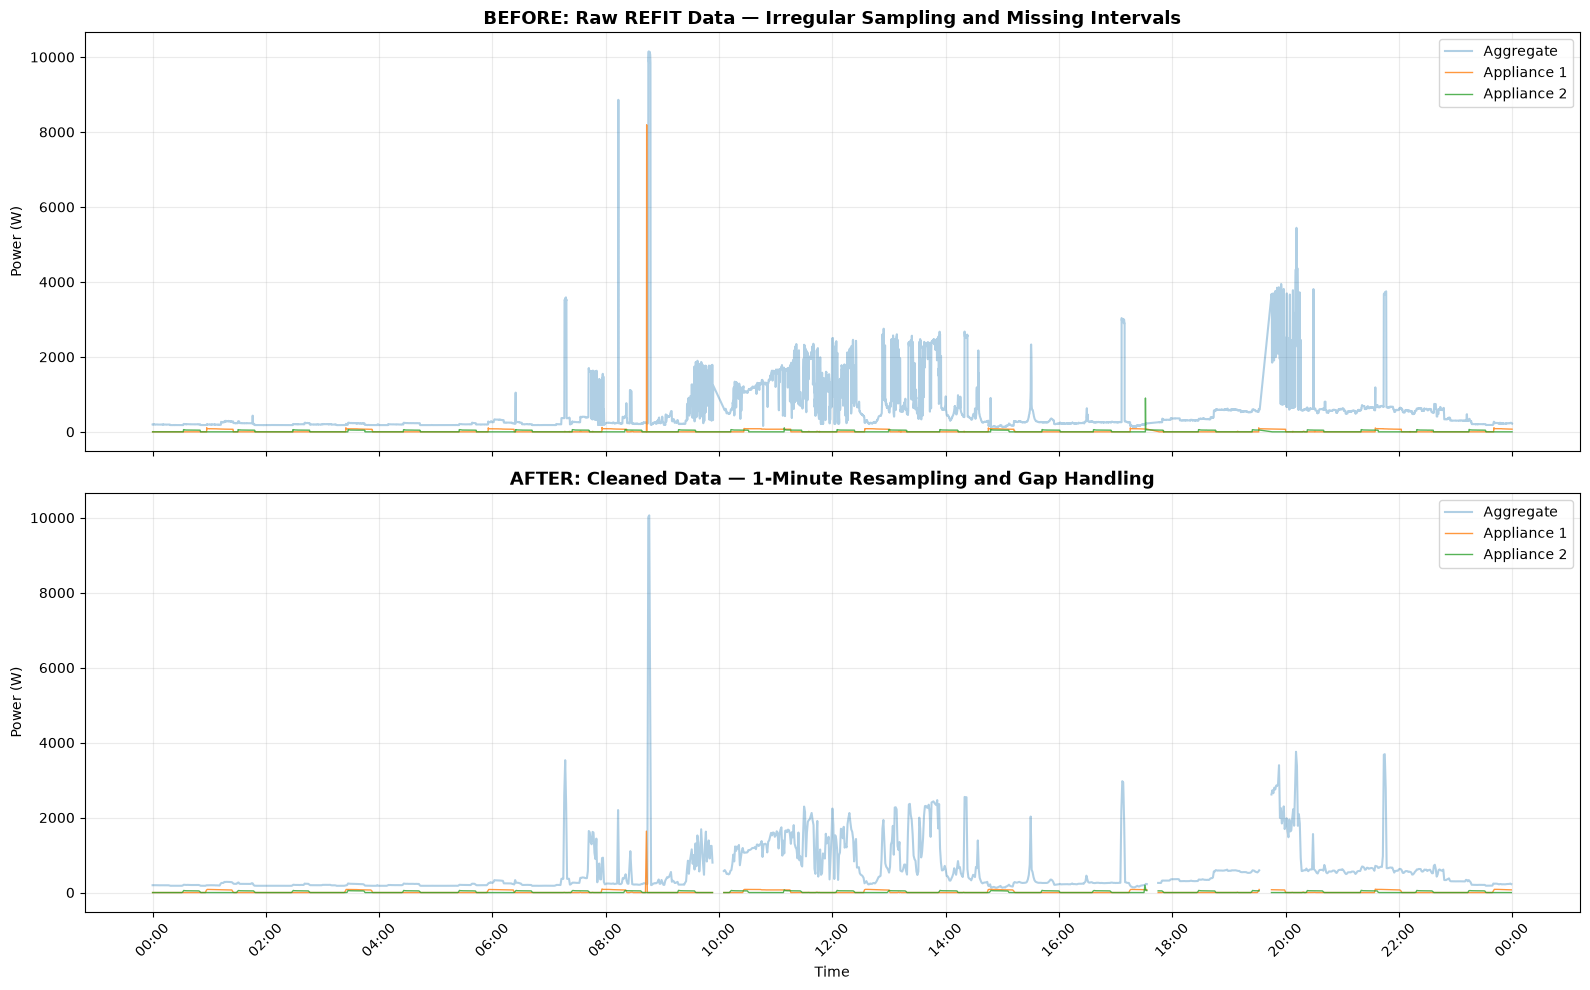

In [32]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Define a specific 24-hour window
start = '2013-10-10 00:00:00'
end = '2013-10-10 23:59:59'

# Slice both datasets
df_raw_slice = df.loc[start:end]
df_clean_slice = df_cleaned.loc[start:end]

# Create figure
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(16, 10),
    sharex=True,
    sharey=True
)

# ============================================================
# BEFORE CLEANING
# ============================================================

axes[0].plot(
    df_raw_slice.index,
    df_raw_slice['Aggregate'],
    label='Aggregate',
    alpha=0.35,
    linewidth=1.5
)

axes[0].plot(
    df_raw_slice.index,
    df_raw_slice['Appliance1'],
    label='Appliance 1',
    alpha=0.8,
    linewidth=1
)

axes[0].plot(
    df_raw_slice.index,
    df_raw_slice['Appliance2'],
    label='Appliance 2',
    alpha=0.8,
    linewidth=1
)

axes[0].set_title(
    'BEFORE: Raw REFIT Data — Irregular Sampling and Missing Intervals',
    fontsize=13,
    fontweight='bold'
)

axes[0].set_ylabel('Power (W)')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.25)

# ============================================================
# AFTER CLEANING
# ============================================================

axes[1].plot(
    df_clean_slice.index,
    df_clean_slice['Aggregate'],
    label='Aggregate',
    alpha=0.35,
    linewidth=1.5
)

axes[1].plot(
    df_clean_slice.index,
    df_clean_slice['Appliance1'],
    label='Appliance 1',
    alpha=0.8,
    linewidth=1
)

axes[1].plot(
    df_clean_slice.index,
    df_clean_slice['Appliance2'],
    label='Appliance 2',
    alpha=0.8,
    linewidth=1
)

axes[1].set_title(
    'AFTER: Cleaned Data — 1-Minute Resampling and Gap Handling',
    fontsize=13,
    fontweight='bold'
)

axes[1].set_ylabel('Power (W)')
axes[1].set_xlabel('Time')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.25)

# ============================================================
# TIME AXIS FORMATTING
# ============================================================

axes[1].xaxis.set_major_locator(mdates.HourLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()